# Indexing a diffraction pattern

This notebook indexes an experimental electron diffraction pattern of Aluminium with pyEMAPS,
step by step: it finds the crystal's orientation and the Miller indices of the spots. It follows
the *al_dpgen.py* and *al_ediom.py* samples, one step per cell.

You'll:

1. generate a database of simulated diffraction patterns for Aluminium;
2. look at the experimental pattern;
3. index it against the database;
4. check the result yourself: the zone axis, the spot spacings and the camera constant.

**Indexing in brief.** At a zone axis $[uvw]$, a diffraction pattern shows the reflections
$\mathbf g = (hkl)$ with $\mathbf g \cdot [uvw] = 0$; see the
[kinematic diffraction notebook](si_dif.ipynb). Indexing works backwards, from the spots to the
orientation. pyEMAPS does it by **template matching**: it simulates kinematic patterns for many
orientations of the crystal, stores them in a database, and compares the experimental pattern
with each one. The best-matching pattern gives the orientation and the spots' indices.

**A licensed feature.** Indexing needs an activated pyEMAPS license. `pyemaps -l trial`, run in a
terminal with an internet connection, activates a free 7-day trial; for a full license, contact
support@emlabsoftware.com. Step 1 checks it.

**Requirements.** pyEMAPS on Windows, with Python 3.12 to 3.15, and Jupyter in the same
environment. The experimental image, *al.img*, comes with pyEMAPS.

The [4D-STEM pattern indexing guide](https://emlab-solutions.github.io/pyemaps/user_guide/indexing.html) covers the
same ground.

## Step 1: Import pyEMAPS and check the license

`StackImage` holds experimental images and runs the 4D-STEM analyses. `stem4d` is pyEMAPS'
4D-STEM engine; `check_license_once` checks the license without printing its details.

In [1]:
import os
from importlib.metadata import version

import numpy as np

import pyemaps
from pyemaps import EMC, Crystal, StackImage, stem4d

print('pyEMAPS', version('pyemaps'))
if stem4d.check_license_once() == stem4d.LICENSE_ACTIVE:
    print('License: active')
else:
    print('No active license: run "pyemaps -l trial" in a terminal for a 7-day trial, '
          'or contact support@emlabsoftware.com.')

# The sample files that come with pyEMAPS, including the experimental image.
SAMPLES = os.path.join(os.path.dirname(pyemaps.__file__), 'samples')
IMAGE_FILE = os.path.join(SAMPLES, 'al.img')

pyEMAPS 2.1.1.dev11
License: active


## Step 2: Load the crystal

Aluminium is face-centred cubic (fcc), space group 225 (*Fm*-3*m*), with one atom per lattice
point. Its structure factor is zero unless *h*, *k* and *l* are all even or all odd, so only
reflections such as (1 1 1), (2 0 0) and (2 2 0) appear.

In [2]:
aluminium = Crystal.from_builtin('Aluminium')
print(aluminium)

Crystal name: Aluminium dw iso
cell: 4.0493 4.0493 4.0493 90.0 90.0 90.0
AL 0.000000 0.000000 0.000000 0.7806 1.000000
spg: 225 1


## Step 3: Generate the pattern database

`generateDPDB` simulates kinematic diffraction patterns of the crystal over a range of
orientations, and saves them in a database file, in the `dpdb` folder of the pyEMAPS data folder.
By default the range is the **standard triangle** of the stereographic projection, between the
[001], [011] and [111] zone axes: for a cubic crystal, every beam direction is equivalent by
symmetry to one inside it.

- `res` sets how finely the triangle is sampled, from 100 to 500 points along its radius. A finer
  database holds more patterns, so it finds the orientation more precisely and takes longer to
  search.
- `xa` fixes the crystal's horizontal axis in the simulated patterns.
- `emc` holds the microscope controls the patterns are simulated with.

The settings are those of the *al_dpgen.py* sample; generating the database takes a few
seconds.

In [3]:
ret, db_file = aluminium.generateDPDB(emc=EMC(zone=(0, 0, 1)), xa=(2, 0, 0), res=200)

*******************************************************************************
* The diffraction pattern database for Aluminium has been generated successfully
* and saved in:
* C:\pyemaps_data\dpdb\Aluminium-20261114110938.bin
*******************************************************************************


## Step 4: Look at the experimental pattern

*al.img* is an experimental diffraction pattern of Aluminium, in pyEMAPS' small-header image
format: an 8-byte header with the width, the height, the number of stacks and the data type,
then the pixels. `loadImage` reads it, and `viewExpImage` shows it.

Image size: 200 x 200 pixels


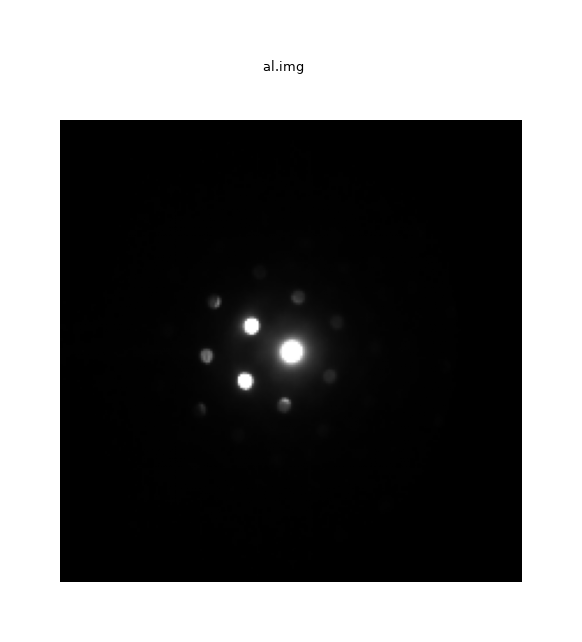

In [4]:
image = StackImage(IMAGE_FILE)
image.loadImage()
print('Image size:', image.dim[0], 'x', image.dim[1], 'pixels')
image.viewExpImage(title='al.img')

The bright spot near the center is the direct beam; the spots around it are the diffracted
beams. Which zone axis is it? That's what indexing finds.

## Step 5: Index the pattern

`indexImage` finds the diffraction peaks in the image, then searches the database for the
pattern that matches them best. It needs some measurements of the image:

| Parameter | Meaning |
|---|---|
| `cc` | the **camera constant**, in pixels per 1/Å: a reflection $\mathbf g$ lands $R = cc\,\lvert\mathbf g\rvert$ pixels from the center |
| `img_center` | the pattern's center, the direct beam, in pixels |
| `sigma` | the estimated width of the peaks, in pixels |
| `rmin` | the radius around the center left out of the peak search, to skip the direct beam |
| `search_box` | the size of the peak search box, in pixels |
| `peak_threshold` | drops weak, noisy peaks, from 0 to 1 |
| `filter_threshold` | screens the database patterns before matching; 0 searches them all |
| `scaling_option` | how the experimental and database intensities are scaled for matching |

The camera constant comes from the microscope: on the detector, $R = \lambda L |\mathbf g|$, so
in pixels $cc = \lambda L / p$, where $L$ is the camera length and $p$ the pixel size.

`indexImage` shows four figures: the database's orientations on the stereographic triangle; the
experimental image; the peaks it found, circled, with the indexed ones labelled by their Miller
indices and the others by (0, 0, 0); and the **matching index map**, which colours each
orientation by how well its pattern matches, with the best in red.

Diffraction Database loaded successfully.
Dimension of stereo projection map: width =76, height=85


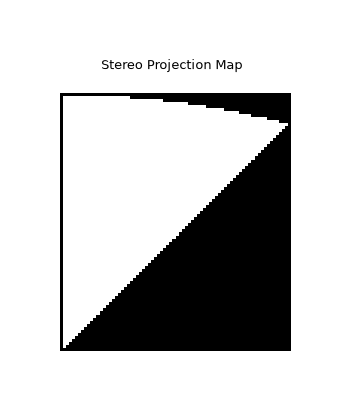

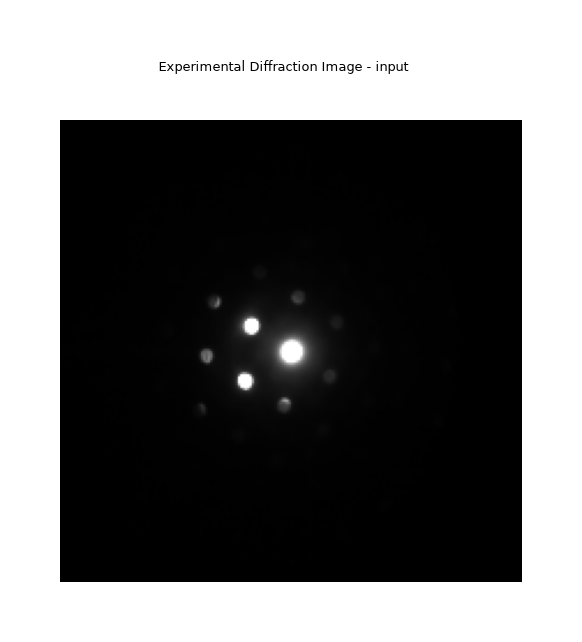

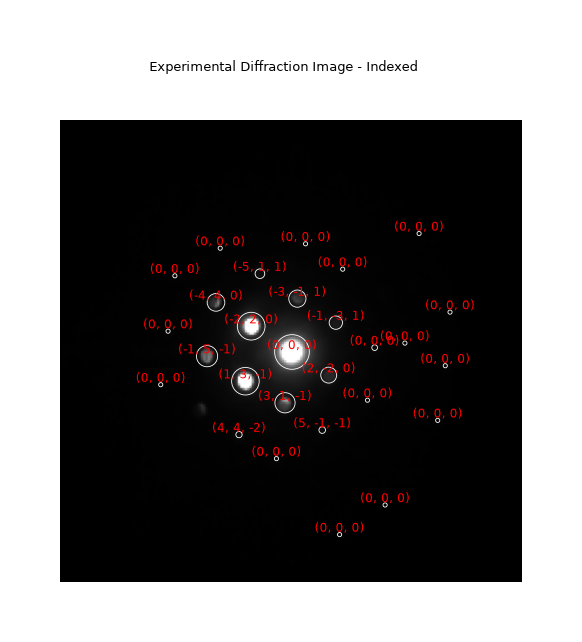

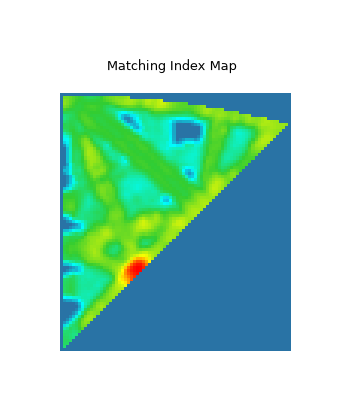



-----------------Indexed Diffraction Pattern Details------------------
 DP #   Miller Index     Distance            DP Loc          Intensity 
indexImage returned 0 (0 means success)


In [5]:
ret = image.indexImage(db_file,
                       cc=29.0,                       # camera constant, pixels per 1/Å
                       sigma=3.0,                     # estimated peak width, in pixels
                       img_center=(99.923, 99.919),   # pattern center, in pixels
                       rmin=10,                       # radius excluded around the center
                       search_box=10.0,               # peak search box size, in pixels
                       scaling_option=(1, 2),         # intensity scaling for matching
                       filter_threshold=0.0,          # 0 searches every database pattern
                       peak_threshold=0.8)            # drops noisy peaks
print('indexImage returned', ret, '(0 means success)')

`indexImage` also prints a summary: the best-matching database pattern, the pattern's
rotation, the correlation, the beam direction and a **reliability index**, where above 5 means
the indexing succeeded. Here the reliability index is 30.5. It also prints a table of the indexed
peaks.

Those come from pyEMAPS' C++ engine, and in Jupyter they appear in the terminal window running
Jupyter, not in the notebook. That's why the table above has its heading but no rows. Until
pyEMAPS returns them to Python, the next step reads the indexed peaks directly from the
engine.

## Step 6: The indexed peaks

For each peak, the table gives its Miller indices, its distance $R$ from the center, the length
$|\mathbf g| = \sqrt{h^2 + k^2 + l^2}/a$ of the reciprocal lattice vector for Aluminium's cubic
cell, and their ratio.

In [6]:
from pyemaps import ediom      # pyEMAPS' indexing engine


def indexed_peaks():
    """The pattern center, and (x, y, (h, k, l)) for each peak the last indexImage indexed."""
    n = ediom.getExpImagePeaks()
    ret, peaks = ediom.getXKDif(n + 1)
    x0, y0 = peaks[0][:2]
    # Each peak is (x, y, radius, (h, k, l), kind); kind 2 marks an indexed peak.
    return (x0, y0), [(x, y, hkl) for x, y, radius, hkl, kind in peaks[1:] if kind == 2]


(x0, y0), peaks = indexed_peaks()
a = aluminium.cell.a
print(f'{len(peaks)} peaks indexed, around the center ({x0:.2f}, {y0:.2f})')
print()
print('  (h  k  l)    R (px)   |g| (1/Å)   R/|g|')
ratios = []
for x, y, hkl in peaks:
    R = np.hypot(x - x0, y - y0)
    g = np.linalg.norm(hkl) / a
    ratios.append(R / g)
    print(f'  ({hkl[0]:2d} {hkl[1]:2d} {hkl[2]:2d})   {R:7.2f}   {g:8.4f}   {R / g:6.2f}')

11 peaks indexed, around the center (99.92, 99.92)

  (h  k  l)    R (px)   |g| (1/Å)   R/|g|
  ( 2 -2  0)     18.81     0.6985    26.92
  (-2  2  0)     20.89     0.6985    29.91
  ( 3  1 -1)     22.20     0.8191    27.11
  (-1 -3  1)     22.83     0.8191    27.87
  (-3 -1  1)     23.20     0.8191    28.33
  ( 1  3 -1)     23.80     0.8191    29.06
  ( 5 -1 -1)     36.27     1.2832    28.26
  (-5  1  1)     36.62     1.2832    28.53
  (-1  5 -1)     36.81     1.2832    28.68
  (-4  4  0)     39.27     1.3970    28.11
  ( 4  4 -2)     42.50     1.4817    28.68


Every indexed reflection has all-even or all-odd indices, as Aluminium's fcc structure
requires.

## Step 7: Check the zone axis

All the indexed reflections lie in one plane of the reciprocal lattice, the zero-order Laue zone,
perpendicular to the zone axis. So the cross product of any two of them, $\mathbf g_1 \times
\mathbf g_2$, points along the zone axis:

In [7]:
from math import gcd

g1 = np.array(peaks[0][2])
g2 = next(np.array(hkl) for x, y, hkl in peaks if np.any(np.cross(g1, hkl)))
uvw = np.cross(g1, g2)
uvw = uvw // gcd(*(int(v) for v in uvw))          # smallest integers
if uvw[np.flatnonzero(uvw)[0]] < 0:              # first nonzero index positive
    uvw = -uvw

print(f'({g1[0]} {g1[1]} {g1[2]}) x ({g2[0]} {g2[1]} {g2[2]}): '
      f'zone axis [{uvw[0]} {uvw[1]} {uvw[2]}]')
print('g . [uvw] for every indexed peak:', [int(np.dot(hkl, uvw)) for x, y, hkl in peaks])

(2 -2 0) x (3 1 -1): zone axis [1 1 4]
g . [uvw] for every indexed peak: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


The pattern is the **[1 1 4] zone axis**, about 19° from [001], on the edge of the standard
triangle between [001] and [111]. Every indexed reflection satisfies $\mathbf g \cdot [1\,1\,4]
= 0$. The engine's summary agrees: its beam direction, (0.058, 0.060, 0.233), is within half a
degree of [1 1 4].

## Step 8: Check the camera constant

If the indexing is right, $R/|\mathbf g|$ should be the camera constant for every peak:

In [8]:
print(f'R/|g| = {np.mean(ratios):.1f} ± {np.std(ratios):.1f} pixels per 1/Å, '
      f'against cc = 29 given to indexImage')

R/|g| = 28.3 ± 0.8 pixels per 1/Å, against cc = 29 given to indexImage


The measured spacings agree with Aluminium's cell and the camera constant within their
scatter, about 3%. Part of the scatter comes from the pattern center. A reflection $\mathbf g$
and its Friedel partner $-\mathbf g$ should be the same distance from the center, but (2 −2 0)
and (−2 2 0) are 18.8 and 20.9 pixels away: the center given to `indexImage` is about a pixel off
the true one.

## Step 9: The best-matching database pattern

`showMatchedDBDP` shows the simulated pattern that matched best, with its spots labelled.
Compare it with the experimental pattern in Step 4.

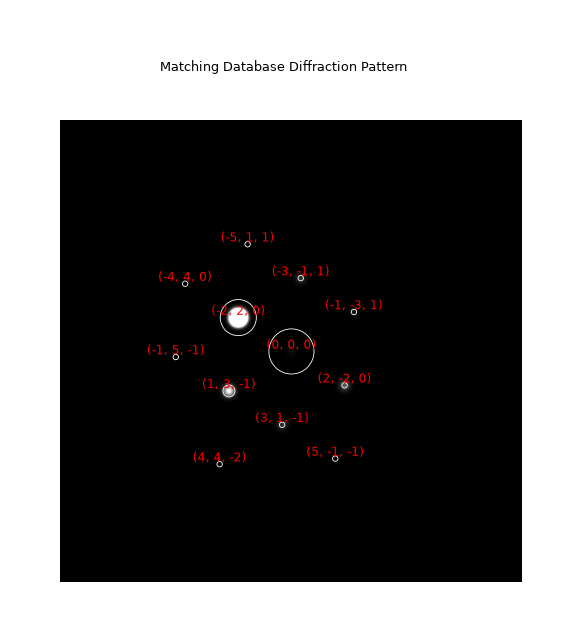

0

In [9]:
StackImage.showMatchedDBDP()

## Try it yourself

1. **Camera constant.** Index the pattern again with `cc=27.0` and `cc=31.0`. How do the
   reliability index (in the terminal) and the number of indexed peaks change?
2. **Pattern center.** Estimate the true center from the midpoints of the Friedel pairs in
   Step 6, such as (2 −2 0) and (−2 2 0). Index again with it. Does the scatter of $R/|g|$
   shrink?
3. **Database resolution.** Generate databases with `res=100` and `res=400`. How long does each
   take, and does the result change?
4. **Simulate it.** With the [kinematic diffraction notebook](si_dif.ipynb), simulate Aluminium
   at the [1 1 4] zone axis (`EMC(zone=(1, 1, 4))`) and compare it with *al.img*.

## Next

- The 4D-STEM imaging notebook, [adf.ipynb](adf.ipynb): bright field, dark field and masked
  images from a 4D-STEM scan.
- The [4D-STEM pattern indexing guide](https://emlab-solutions.github.io/pyemaps/user_guide/indexing.html), and the
  references for [`generateDPDB`](https://emlab-solutions.github.io/pyemaps/api/crystals.html#pyemaps.crystals.Crystal.generateDPDB)
  and [`indexImage`](https://emlab-solutions.github.io/pyemaps/api/images.html#pyemaps.stackimg.StackImage.indexImage).

## Further reading

J. C. H. Spence and J. M. Zuo, *Electron Microdiffraction* (Plenum, New York, 1992),
[doi:10.1007/978-1-4899-2353-0](https://doi.org/10.1007/978-1-4899-2353-0):

- chapter 2, *The Geometry of CBED Patterns*, for zone axes and indexing in Steps 6 to 8.

J. M. Zuo and J. C. H. Spence, *Advanced Transmission Electron Microscopy* (Springer, New York,
2017), [doi:10.1007/978-1-4939-6607-3](https://doi.org/10.1007/978-1-4939-6607-3), a newer and
broader book by the same authors:

- chapter 3, *The Geometry of Electron Diffraction Patterns*, for zone axes, the camera constant
  and indexing in Steps 5 to 8.